In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode


In [2]:
PROJECT_DIR = Path("..").resolve()

DATA_DIR = PROJECT_DIR / "raw/airbus-ship-detection/train_v2"
ANNOTATION_PATH = (
    PROJECT_DIR / "raw/airbus-ship-detection/train_ship_segmentations_v2.csv"
)

SPLIT_DIR = PROJECT_DIR / "splits"
TRAIN_SPLIT_PATH = SPLIT_DIR / "train.csv"
VALIDATION_SPLIT_PATH = SPLIT_DIR / "validation.csv"
TEST_SPLIT_PATH = SPLIT_DIR / "test.csv"

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
BEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "simclr_best.pt"

IMAGE_SIZE = 224
BATCH_SIZE = 128
NUM_WORKERS = 4
SEED = 42

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print(f"Project directory: {PROJECT_DIR}")
print(f"Device: {DEVICE}")
print(f"AMP enabled: {USE_AMP}")
print(f"Best checkpoint: {BEST_CHECKPOINT_PATH}")


Project directory: /home/abhi/Dev/varuna-ssl
Device: cuda
AMP enabled: True
Best checkpoint: /home/abhi/Dev/varuna-ssl/checkpoints/simclr_best.pt


In [3]:
train_df = pd.read_csv(TRAIN_SPLIT_PATH)
validation_df = pd.read_csv(VALIDATION_SPLIT_PATH)
test_df = pd.read_csv(TEST_SPLIT_PATH)

print("Dataset splits loaded successfully")

print(f"Training images:   {len(train_df):,}")
print(f"Validation images: {len(validation_df):,}")
print(f"Test images:       {len(test_df):,}")

print("\nTest class distribution:")
print(test_df["has_ship"].value_counts().rename({0: "No Ship", 1: "Ship"}))


Dataset splits loaded successfully
Training images:   134,789
Validation images: 28,883
Test images:       28,884

Test class distribution:
has_ship
No Ship    22500
Ship        6384
Name: count, dtype: int64


In [4]:
class SimCLR(nn.Module):
    def __init__(self, projection_dim=128):
        super().__init__()

        from torchvision.models import resnet18

        self.encoder = resnet18(weights=None)
        self.encoder.fc = nn.Identity()

        self.projector = nn.Sequential(
            nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, projection_dim)
        )

    def forward(self, x):
        features = self.encoder(x)
        projections = self.projector(features)
        projections = nn.functional.normalize(projections, dim=1)

        return features, projections


# Load checkpoint
checkpoint = torch.load(
    BEST_CHECKPOINT_PATH, map_location=DEVICE, weights_only=False
)

# Recreate model using saved configuration
projection_dim = checkpoint["config"]["projection_dim"]

model = SimCLR(projection_dim=projection_dim).to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("SimCLR checkpoint loaded successfully")
print(f"Checkpoint epoch: {checkpoint['epoch']}")
print(f"Device: {DEVICE}")


SimCLR checkpoint loaded successfully
Checkpoint epoch: 5
Device: cuda


In [5]:
class AirbusEvaluationDataset(Dataset):
    def __init__(self, image_dir, dataframe):
        self.image_dir = Path(image_dir)
        self.image_ids = dataframe["ImageId"].tolist()
        self.labels = dataframe["has_ship"].astype(int).tolist()

        self.transform = transforms.Compose(
            [
                transforms.Resize(
                    256, interpolation=InterpolationMode.BICUBIC
                ),
                transforms.CenterCrop(IMAGE_SIZE),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)
                ),
            ]
        )

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_path = self.image_dir / self.image_ids[index]

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image.load()

        return self.transform(image), self.labels[index]


In [6]:
from PIL import ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

In [7]:
def extract_features(dataframe):
    dataset = AirbusEvaluationDataset(DATA_DIR, dataframe)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP,
        persistent_workers=NUM_WORKERS > 0,
    )

    features = []
    labels = []

    with torch.inference_mode():
        for images, batch_labels in loader:
            images = images.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP
            ):
                batch_features = model.encoder(images)

            features.append(batch_features.float().cpu())
            labels.append(batch_labels)

    return torch.cat(features), torch.cat(labels)


train_features, train_labels = extract_features(train_df)
test_features, test_labels = extract_features(test_df)

print("Feature extraction completed")
print(f"Training features: {train_features.shape}")
print(f"Test features: {test_features.shape}")


Feature extraction completed
Training features: torch.Size([134789, 512])
Test features: torch.Size([28884, 512])


In [8]:
classifier = nn.Linear(train_features.shape[1], 2).to(DEVICE)

class_counts = torch.bincount(train_labels, minlength=2).float()
class_weights = (len(train_labels) / (2 * class_counts)).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(
    classifier.parameters(), lr=1e-3, weight_decay=1e-4
)

probe_dataset = torch.utils.data.TensorDataset(train_features, train_labels)

generator = torch.Generator().manual_seed(SEED)

probe_loader = DataLoader(
    probe_dataset, batch_size=1024, shuffle=True, generator=generator
)

classifier.train()

for epoch in range(10):
    total_loss = 0

    for features, labels in probe_loader:
        features = features.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = classifier(features)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch + 1}/10 | Loss: {total_loss / len(probe_loader):.4f}")

classifier.eval()
print("Linear classifier training completed")


Epoch 1/10 | Loss: 0.4212
Epoch 2/10 | Loss: 0.3781
Epoch 3/10 | Loss: 0.3684
Epoch 4/10 | Loss: 0.3617
Epoch 5/10 | Loss: 0.3567
Epoch 6/10 | Loss: 0.3524
Epoch 7/10 | Loss: 0.3498
Epoch 8/10 | Loss: 0.3473
Epoch 9/10 | Loss: 0.3443
Epoch 10/10 | Loss: 0.3428
Linear classifier training completed


In [9]:
with torch.inference_mode():
    test_logits = classifier(test_features.to(DEVICE))

    test_probabilities = torch.softmax(test_logits, dim=1).cpu().numpy()

    test_predictions = test_logits.argmax(dim=1).cpu().numpy()

actual_labels = test_labels.numpy()

print("Test predictions generated successfully")
print(f"Total predictions: {len(test_predictions):,}")


Test predictions generated successfully
Total predictions: 28,884


In [10]:
print(
    classification_report(
        actual_labels,
        test_predictions,
        target_names=["No Ship", "Ship"],
        digits=4,
    )
)


              precision    recall  f1-score   support

     No Ship     0.9459    0.8920    0.9182     22500
        Ship     0.6831    0.8203    0.7455      6384

    accuracy                         0.8762     28884
   macro avg     0.8145    0.8562    0.8318     28884
weighted avg     0.8879    0.8762    0.8800     28884



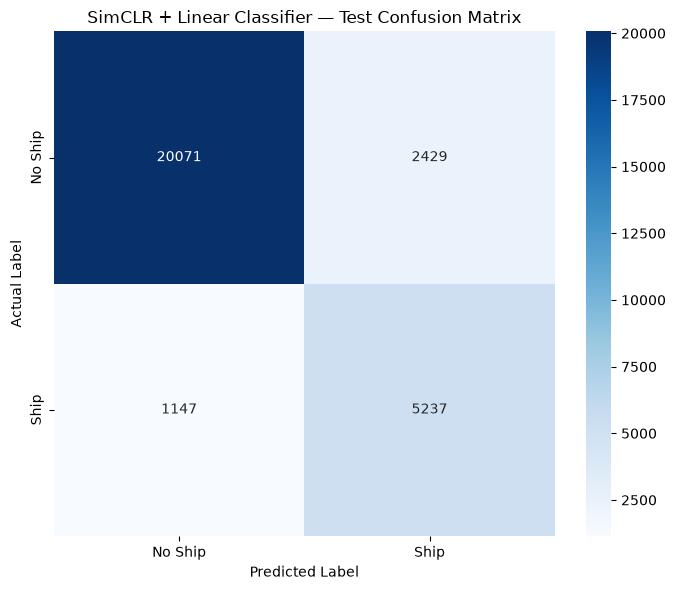

In [11]:
cm = confusion_matrix(actual_labels, test_predictions)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Ship", "Ship"],
    yticklabels=["No Ship", "Ship"],
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SimCLR + Linear Classifier — Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [12]:
prediction_groups = {
    "True Positive": np.where((actual_labels == 1) & (test_predictions == 1))[
        0
    ],
    "False Negative": np.where((actual_labels == 1) & (test_predictions == 0))[
        0
    ],
    "False Positive": np.where((actual_labels == 0) & (test_predictions == 1))[
        0
    ],
    "True Negative": np.where((actual_labels == 0) & (test_predictions == 0))[
        0
    ],
}

for group, indices in prediction_groups.items():
    print(f"{group}: {len(indices):,}")


True Positive: 5,237
False Negative: 1,147
False Positive: 2,429
True Negative: 20,071


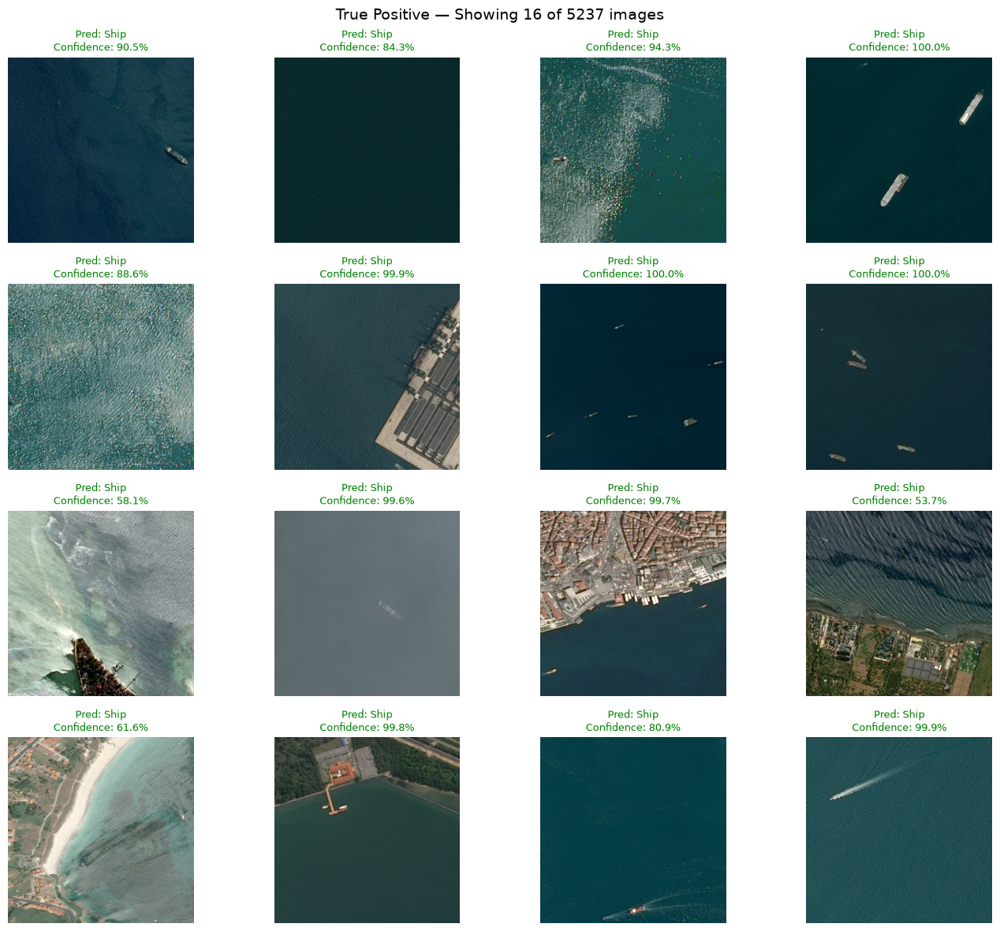

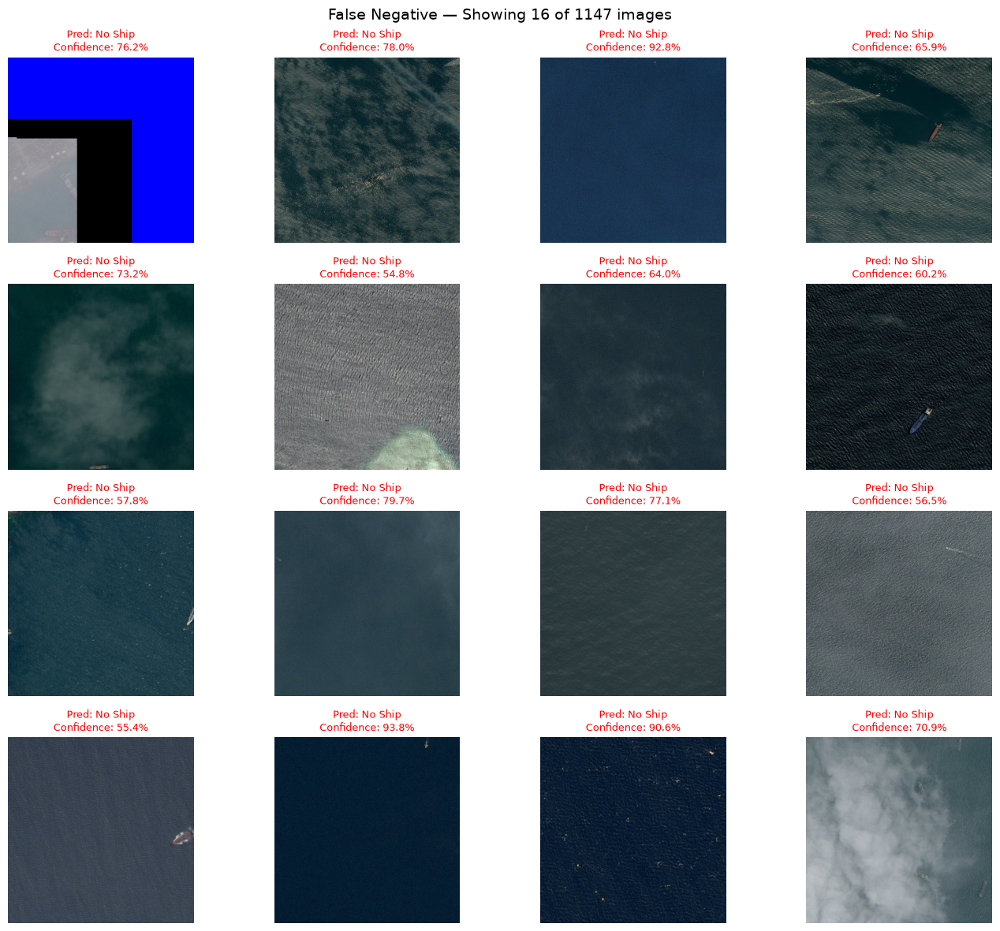

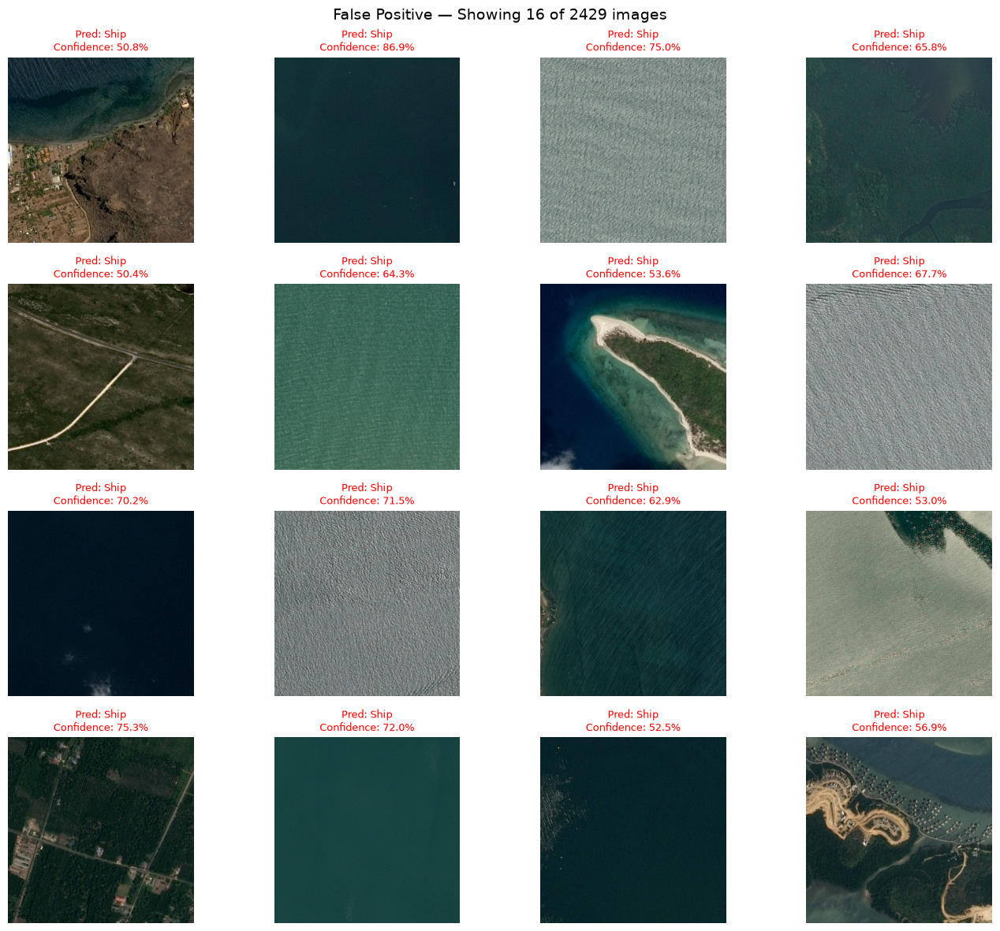

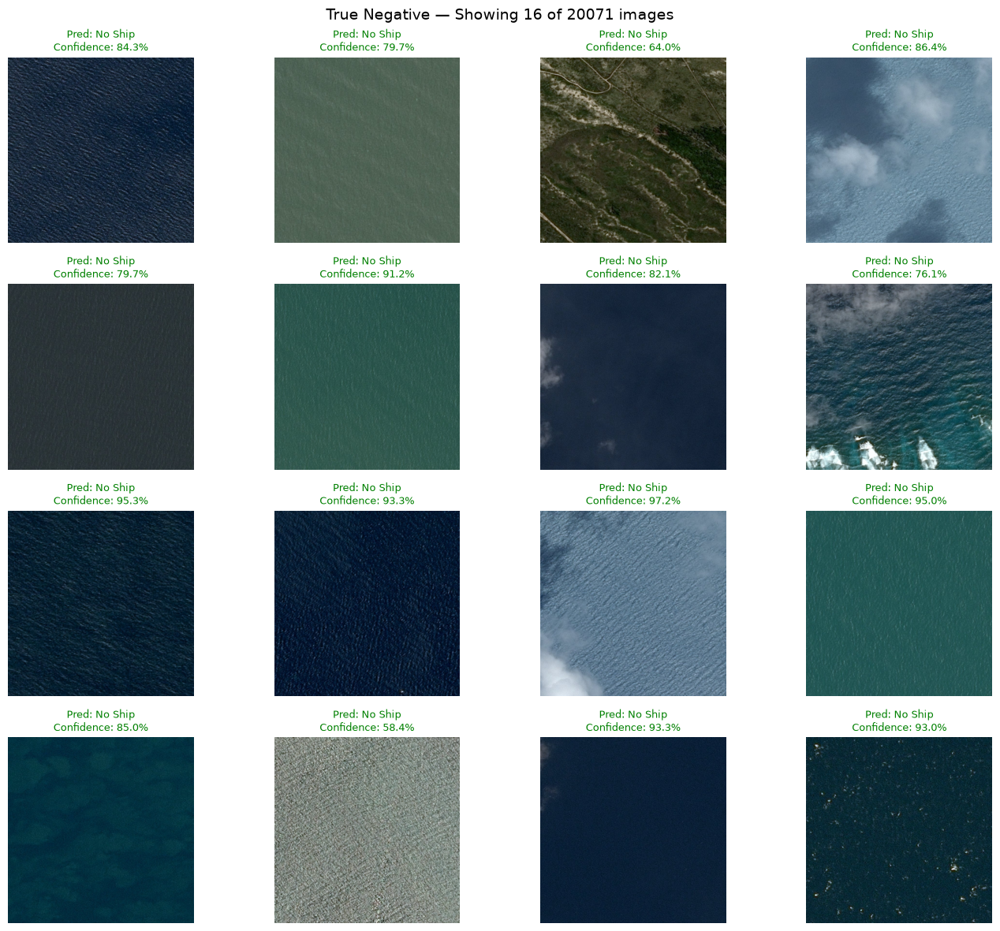

In [13]:
NUM_IMAGES = 16
rng = np.random.default_rng(SEED)

for group, indices in prediction_groups.items():
    selected = rng.choice(
        indices, size=min(NUM_IMAGES, len(indices)), replace=False
    )

    fig, axes = plt.subplots(4, 4, figsize=(14, 12))
    axes = axes.flatten()

    for ax, idx in zip(axes, selected):
        image_id = test_df.iloc[idx]["ImageId"]

        image_path = DATA_DIR / image_id

        with Image.open(image_path) as image:
            ax.imshow(image.convert("RGB"))

        predicted = test_predictions[idx]
        confidence = test_probabilities[idx, predicted]

        correct = actual_labels[idx] == predicted

        ax.set_title(
            f"Pred: {'Ship' if predicted else 'No Ship'}\n"
            f"Confidence: {confidence:.1%}",
            fontsize=9,
            color="green" if correct else "red",
        )

        ax.axis("off")

    for ax in axes[len(selected) :]:
        ax.axis("off")

    fig.suptitle(
        f"{group} — Showing {len(selected)} of {len(indices)} images",
        fontsize=14,
    )

    plt.tight_layout()
    plt.show()


In [14]:
annotations = pd.read_csv(ANNOTATION_PATH)

ship_annotations = annotations.dropna(subset=["EncodedPixels"])

print(f"Total annotation rows: {len(annotations):,}")
print(f"Rows containing ship masks: {len(ship_annotations):,}")
print(f"Unique images with ships: {ship_annotations['ImageId'].nunique():,}")


Total annotation rows: 231,723
Rows containing ship masks: 81,723
Unique images with ships: 42,556


In [15]:
def decode_rle(encoded_pixels, height=768, width=768):
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(encoded_pixels):
        return mask.reshape((height, width))

    values = np.asarray(encoded_pixels.split(), dtype=np.int64)

    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    for start, end in zip(starts, ends):
        mask[start:end] = 1

    return mask.reshape((width, height)).T


In [16]:
def get_ship_statistics(image_id):
    rows = ship_annotations[ship_annotations["ImageId"] == image_id]

    combined_mask = np.zeros((768, 768), dtype=np.uint8)

    for encoded in rows["EncodedPixels"]:
        combined_mask |= decode_rle(encoded)

    ys, xs = np.where(combined_mask > 0)

    if len(xs) == 0:
        return None

    x_min, x_max = xs.min(), xs.max()
    y_min, y_max = ys.min(), ys.max()

    bbox_width = x_max - x_min + 1
    bbox_height = y_max - y_min + 1

    ship_area = len(xs)

    return {
        "ImageId": image_id,
        "ship_pixels": ship_area,
        "coverage_percent": ship_area / (768 * 768) * 100,
        "bbox_width": bbox_width,
        "bbox_height": bbox_height,
        "width_at_224": bbox_width * IMAGE_SIZE / 768,
        "height_at_224": bbox_height * IMAGE_SIZE / 768,
    }


In [17]:
ship_test_indices = np.where(actual_labels == 1)[0]

ship_statistics = []

for idx in ship_test_indices:
    image_id = test_df.iloc[idx]["ImageId"]

    stats = get_ship_statistics(image_id)

    if stats is not None:
        stats["test_index"] = idx
        stats["prediction"] = test_predictions[idx]
        stats["prediction_group"] = (
            "True Positive" if test_predictions[idx] == 1 else "False Negative"
        )

        ship_statistics.append(stats)

size_df = pd.DataFrame(ship_statistics)

print(f"Ship images analysed: {len(size_df):,}")
display(size_df.head())


Ship images analysed: 6,384


,ImageId,ship_pixels,coverage_percent,bbox_width,bbox_height,width_at_224,height_at_224,test_index,prediction,prediction_group
0,300a19052.jpg,3368,0.571018,412,342,120.166667,99.750000,5,1,True Positive
1,cf2e084ce.jpg,5216,0.884332,173,57,50.458333,16.625000,7,0,False Negative
2,d083f3e15.jpg,12869,2.181837,456,662,133.000000,193.083333,15,1,True Positive
3,a701b9142.jpg,1257,0.213114,127,86,37.041667,25.083333,27,1,True Positive
4,cc46535db.jpg,4340,0.735813,162,37,47.250000,10.791667,28,1,True Positive


In [18]:
comparison = size_df.groupby("prediction_group").agg(
    images=("ImageId", "count"),
    median_coverage=("coverage_percent", "median"),
    median_ship_pixels=("ship_pixels", "median"),
    median_bbox_width=("bbox_width", "median"),
    median_bbox_height=("bbox_height", "median"),
    median_width_224=("width_at_224", "median"),
    median_height_224=("height_at_224", "median"),
)

display(comparison)


,images,median_coverage,median_ship_pixels,median_bbox_width,median_bbox_height,median_width_224,median_height_224
prediction_group,,,,,,,
False Negative,1147,0.057983,342.0,33.0,27.0,9.625000,7.875
True Positive,5237,0.260756,1538.0,103.0,72.0,30.041667,21.000


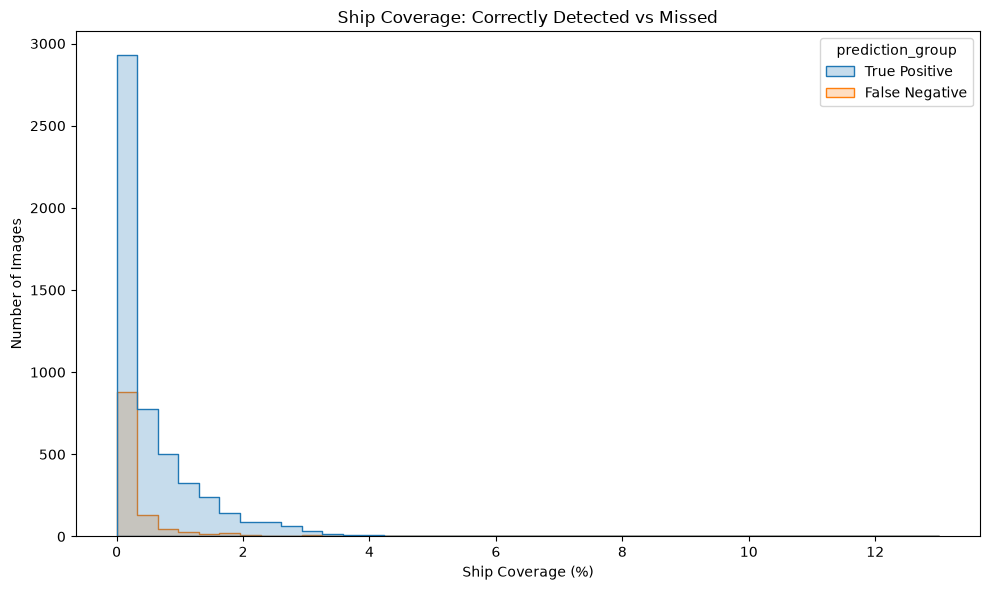

In [19]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=size_df,
    x="coverage_percent",
    hue="prediction_group",
    bins=40,
    element="step",
    stat="count",
    common_norm=False,
)

plt.xlabel("Ship Coverage (%)")
plt.ylabel("Number of Images")
plt.title("Ship Coverage: Correctly Detected vs Missed")
plt.tight_layout()
plt.show()


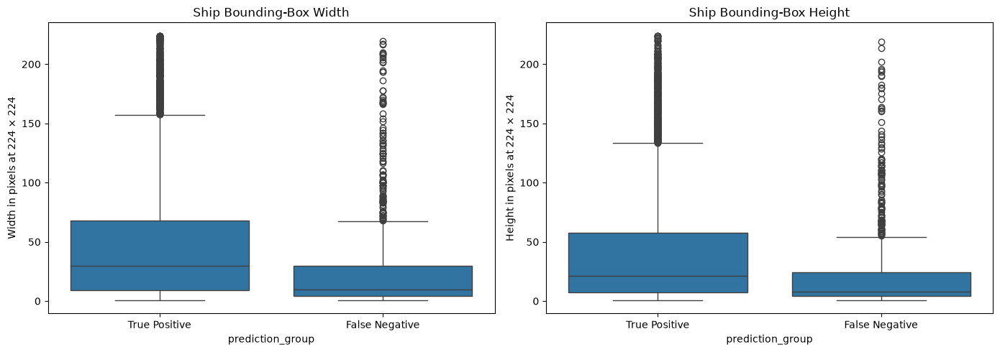

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=size_df, x="prediction_group", y="width_at_224", ax=axes[0])

axes[0].set_title("Ship Bounding-Box Width")
axes[0].set_ylabel("Width in pixels at 224 × 224")

sns.boxplot(data=size_df, x="prediction_group", y="height_at_224", ax=axes[1])

axes[1].set_title("Ship Bounding-Box Height")
axes[1].set_ylabel("Height in pixels at 224 × 224")

plt.tight_layout()
plt.show()


In [21]:
coverage_bins = [-np.inf, 0.01, 0.05, 0.1, 0.5, 1, 2, 5, np.inf]

coverage_labels = [
    "<0.01%",
    "0.01-0.05%",
    "0.05-0.1%",
    "0.1-0.5%",
    "0.5-1%",
    "1-2%",
    "2-5%",
    ">5%",
]

size_df["coverage_group"] = pd.cut(
    size_df["coverage_percent"],
    bins=coverage_bins,
    labels=coverage_labels,
    right=False,
)

coverage_analysis = size_df.groupby("coverage_group", observed=False).agg(
    images=("ImageId", "count"), detected=("prediction", "sum")
)

coverage_analysis["missed"] = (
    coverage_analysis["images"] - coverage_analysis["detected"]
)

coverage_analysis["detection_rate"] = (
    coverage_analysis["detected"] / coverage_analysis["images"] * 100
)

display(coverage_analysis)


,images,detected,missed,detection_rate
coverage_group,,,,
<0.01%,375,277,98,73.866667
0.01–0.05%,1536,1086,450,70.703125
0.05–0.1%,613,476,137,77.650897
0.1–0.5%,1894,1597,297,84.318902
0.5–1%,884,803,81,90.837104
1–2%,748,688,60,91.978610
2–5%,327,303,24,92.660550
>5%,7,7,0,100.000000


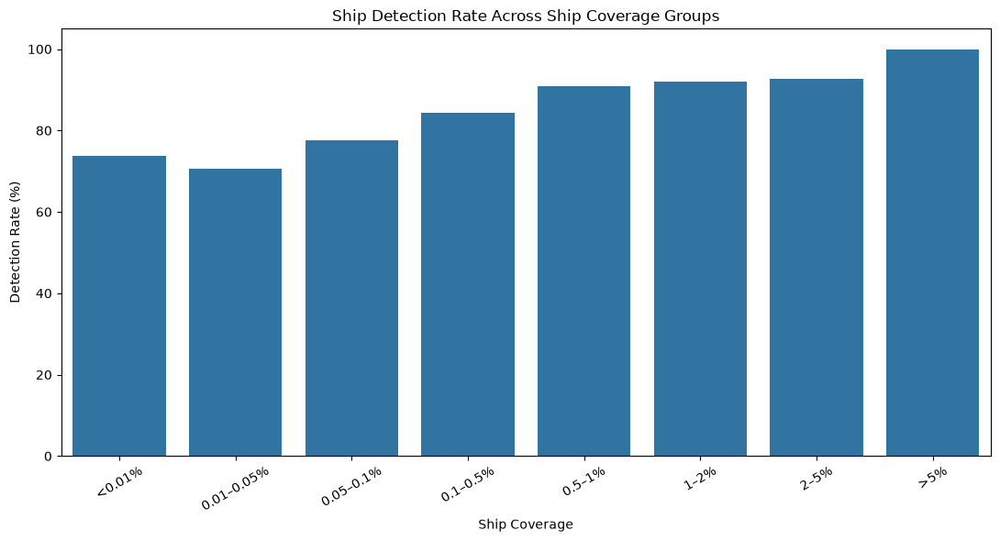

In [22]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=coverage_analysis.reset_index(),
    x="coverage_group",
    y="detection_rate",
)

plt.xlabel("Ship Coverage")
plt.ylabel("Detection Rate (%)")
plt.title("Ship Detection Rate Across Ship Coverage Groups")
plt.ylim(0, 105)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


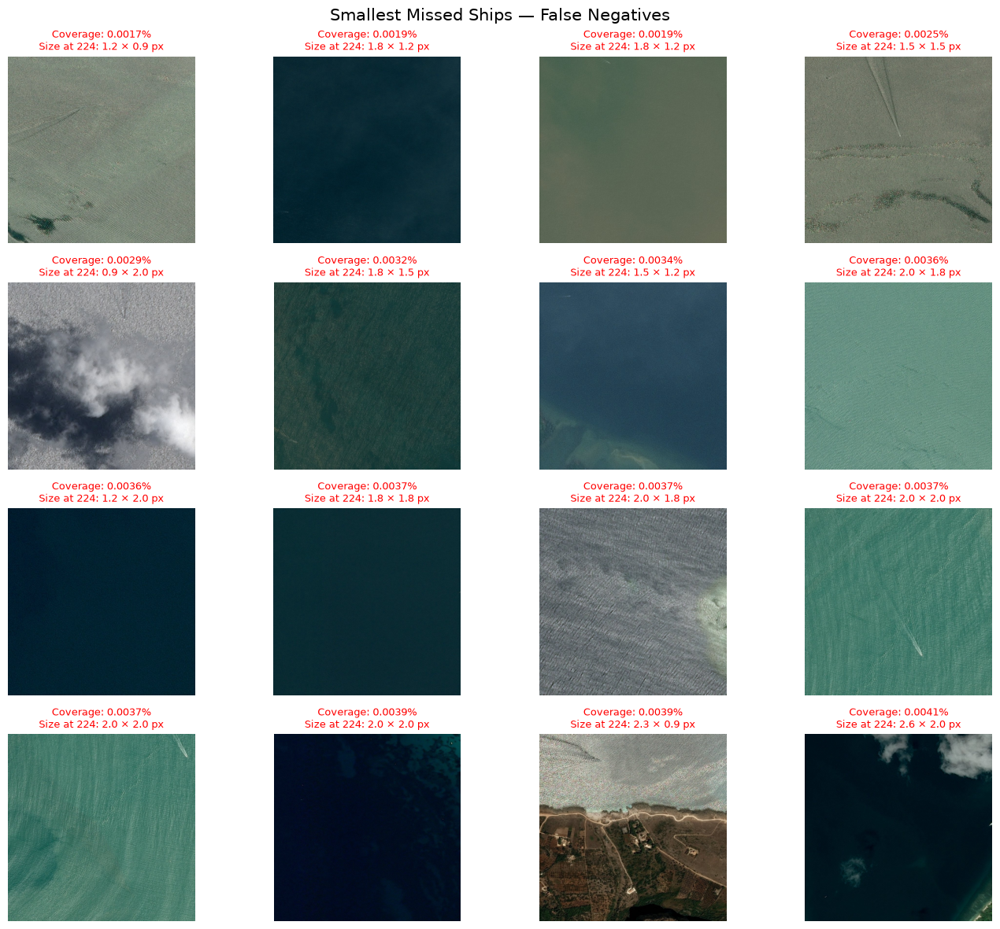

In [23]:
smallest_missed = size_df[
    size_df["prediction_group"] == "False Negative"
].nsmallest(16, "coverage_percent")

fig, axes = plt.subplots(4, 4, figsize=(14, 12))
axes = axes.flatten()

for ax, (_, row) in zip(axes, smallest_missed.iterrows()):
    image_path = DATA_DIR / row["ImageId"]

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"Coverage: {row['coverage_percent']:.4f}%\n"
        f"Size at 224: "
        f"{row['width_at_224']:.1f} × "
        f"{row['height_at_224']:.1f} px",
        color="red",
        fontsize=9,
    )

    ax.axis("off")

for ax in axes[len(smallest_missed) :]:
    ax.axis("off")

plt.suptitle("Smallest Missed Ships — False Negatives", fontsize=15)
plt.tight_layout()
plt.show()


In [24]:
print("SIMCLR MODEL ANALYSIS")
print("=" * 50)

print(f"Test images: {len(actual_labels):,}")
print(f"Correct predictions: {(actual_labels == test_predictions).sum():,}")
print(f"Incorrect predictions: {(actual_labels != test_predictions).sum():,}")

print(f"\nShip images: {(actual_labels == 1).sum():,}")
print(f"Detected ships: {len(prediction_groups['True Positive']):,}")
print(f"Missed ships: {len(prediction_groups['False Negative']):,}")

print("\nShip size comparison:")
display(comparison)

print("\nDetection by ship coverage:")
display(coverage_analysis)


SIMCLR MODEL ANALYSIS
Test images: 28,884
Correct predictions: 25,308
Incorrect predictions: 3,576

Ship images: 6,384
Detected ships: 5,237
Missed ships: 1,147

Ship size comparison:


,images,median_coverage,median_ship_pixels,median_bbox_width,median_bbox_height,median_width_224,median_height_224
prediction_group,,,,,,,
False Negative,1147,0.057983,342.0,33.0,27.0,9.625000,7.875
True Positive,5237,0.260756,1538.0,103.0,72.0,30.041667,21.000



Detection by ship coverage:


,images,detected,missed,detection_rate
coverage_group,,,,
<0.01%,375,277,98,73.866667
0.01–0.05%,1536,1086,450,70.703125
0.05–0.1%,613,476,137,77.650897
0.1–0.5%,1894,1597,297,84.318902
0.5–1%,884,803,81,90.837104
1–2%,748,688,60,91.978610
2–5%,327,303,24,92.660550
>5%,7,7,0,100.000000


In [25]:
# Normalize encoder representations
normalized_test_features = torch.nn.functional.normalize(
    test_features, p=2, dim=1
)

print("Representation extraction ready")
print(f"Feature shape: {normalized_test_features.shape}")
print(f"Feature dimension: {normalized_test_features.shape[1]}")


Representation extraction ready
Feature shape: torch.Size([28884, 512])
Feature dimension: 512


In [26]:
# Define small-ship threshold using the original coverage analysis
SMALL_SHIP_THRESHOLD = 0.1

# Map ship statistics back to test indices
ship_size_lookup = size_df.set_index("test_index")["coverage_percent"]

# Create groups
small_ship_indices = np.array(
    [
        idx
        for idx in np.where(actual_labels == 1)[0]
        if ship_size_lookup.loc[idx] < SMALL_SHIP_THRESHOLD
    ]
)

large_ship_indices = np.array(
    [
        idx
        for idx in np.where(actual_labels == 1)[0]
        if ship_size_lookup.loc[idx] >= SMALL_SHIP_THRESHOLD
    ]
)

no_ship_indices = np.where(actual_labels == 0)[0]

print(f"Small ships: {len(small_ship_indices):,}")
print(f"Large ships: {len(large_ship_indices):,}")
print(f"No-ship images: {len(no_ship_indices):,}")


Small ships: 2,524
Large ships: 3,860
No-ship images: 22,500


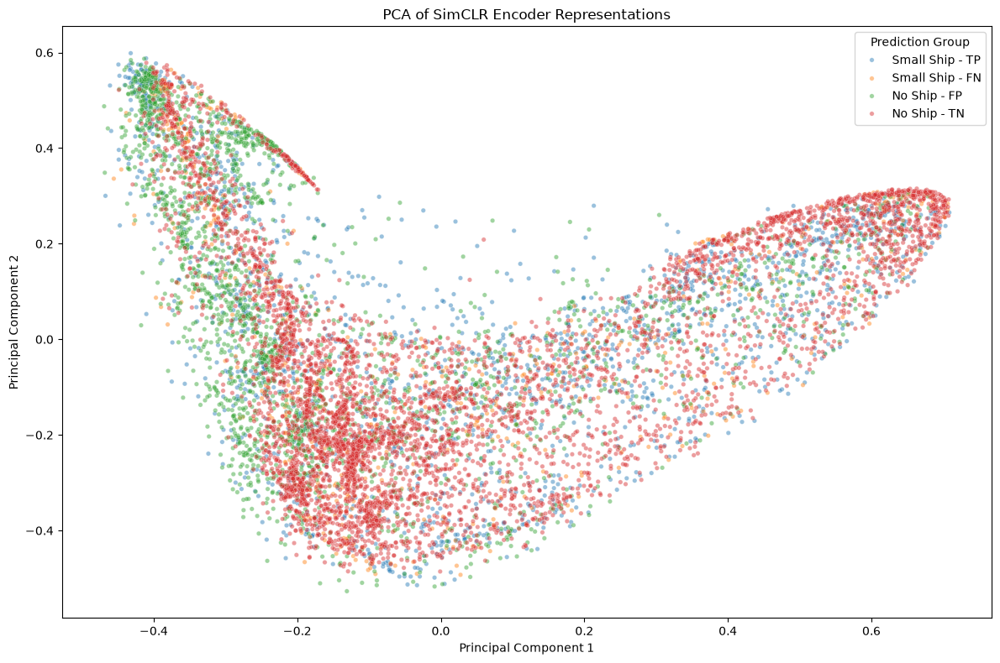

Explained variance: 20.38%


In [27]:
from sklearn.decomposition import PCA

# Identify the four groups
small_ship_tp = np.array(
    [idx for idx in small_ship_indices if test_predictions[idx] == 1]
)

small_ship_fn = np.array(
    [idx for idx in small_ship_indices if test_predictions[idx] == 0]
)

no_ship_fp = np.where((actual_labels == 0) & (test_predictions == 1))[0]

no_ship_tn = np.where((actual_labels == 0) & (test_predictions == 0))[0]

# Sample correctly classified no-ship images for readability
rng = np.random.default_rng(SEED)

sampled_no_ship_tn = rng.choice(
    no_ship_tn, size=min(5000, len(no_ship_tn)), replace=False
)

selected_indices = np.concatenate(
    [small_ship_tp, small_ship_fn, no_ship_fp, sampled_no_ship_tn]
)

# Convert selected representations to NumPy
features = normalized_test_features[selected_indices].numpy()

# Reduce 512 dimensions to 2
pca = PCA(n_components=2, random_state=SEED)
reduced_features = pca.fit_transform(features)

# Create plotting dataframe
pca_df = pd.DataFrame(
    {
        "PC1": reduced_features[:, 0],
        "PC2": reduced_features[:, 1],
        "Group": (
            ["Small Ship - TP"] * len(small_ship_tp)
            + ["Small Ship - FN"] * len(small_ship_fn)
            + ["No Ship - FP"] * len(no_ship_fp)
            + ["No Ship - TN"] * len(sampled_no_ship_tn)
        ),
    }
)

# Visualize
plt.figure(figsize=(12, 8))

sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Group", alpha=0.45, s=15)

plt.title("PCA of SimCLR Encoder Representations")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Prediction Group")
plt.tight_layout()
plt.show()

print(
    "Explained variance:", f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)


In [28]:
# Normalize training representations
normalized_train_features = torch.nn.functional.normalize(
    train_features, p=2, dim=1
)

# Separate training representations by class
train_ship_features = normalized_train_features[train_labels == 1]
train_no_ship_features = normalized_train_features[train_labels == 0]

# Calculate class prototypes
ship_prototype = torch.nn.functional.normalize(
    train_ship_features.mean(dim=0), dim=0
)

no_ship_prototype = torch.nn.functional.normalize(
    train_no_ship_features.mean(dim=0), dim=0
)

print("Class prototypes created")
print(f"Ship prototype: {ship_prototype.shape}")
print(f"No-ship prototype: {no_ship_prototype.shape}")


Class prototypes created
Ship prototype: torch.Size([512])
No-ship prototype: torch.Size([512])


In [29]:
# Calculate similarity against both prototypes
ship_similarity = (normalized_test_features @ ship_prototype).numpy()

no_ship_similarity = (normalized_test_features @ no_ship_prototype).numpy()

# Positive margin means closer to ship prototype
# Negative margin means closer to no-ship prototype
similarity_margin = ship_similarity - no_ship_similarity

# Build analysis dataframe
similarity_df = pd.DataFrame(
    {
        "ImageId": test_df["ImageId"],
        "actual": actual_labels,
        "prediction": test_predictions,
        "ship_similarity": ship_similarity,
        "no_ship_similarity": no_ship_similarity,
        "similarity_margin": similarity_margin,
    }
)

# Attach ship coverage for ship-containing images
similarity_df["coverage_percent"] = np.nan

similarity_df.loc[size_df["test_index"].values, "coverage_percent"] = size_df[
    "coverage_percent"
].values

similarity_df["group"] = "No Ship"

similarity_df.loc[(actual_labels == 1) & (test_predictions == 1), "group"] = (
    "Ship - TP"
)

similarity_df.loc[(actual_labels == 1) & (test_predictions == 0), "group"] = (
    "Ship - FN"
)

print("Cosine similarity analysis completed")


Cosine similarity analysis completed


In [30]:
similarity_comparison = similarity_df.groupby("group").agg(
    images=("ImageId", "count"),
    mean_ship_similarity=("ship_similarity", "mean"),
    mean_no_ship_similarity=("no_ship_similarity", "mean"),
    mean_margin=("similarity_margin", "mean"),
    median_margin=("similarity_margin", "median"),
)

display(similarity_comparison)


,images,mean_ship_similarity,mean_no_ship_similarity,mean_margin,median_margin
group,,,,,
No Ship,22500,0.356092,0.417875,-0.061782,-0.070107
Ship - FN,1147,0.376415,0.416959,-0.040544,-0.039625
Ship - TP,5237,0.546575,0.445926,0.100649,0.094293


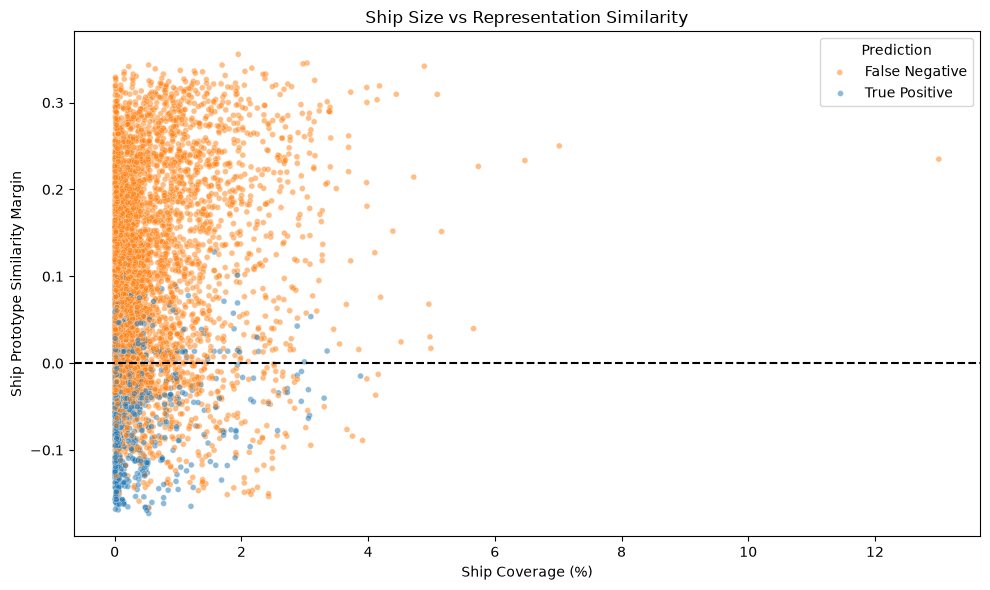

In [32]:
ship_similarity_analysis = similarity_df[similarity_df["actual"] == 1].copy()


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=ship_similarity_analysis,
    x="coverage_percent",
    y="similarity_margin",
    hue="prediction",
    hue_order=[0, 1],
    palette={0: "tab:blue", 1: "tab:orange"},
    alpha=0.5,
    s=18,
)

plt.axhline(0, linestyle="--", color="black")

plt.xlabel("Ship Coverage (%)")
plt.ylabel("Ship Prototype Similarity Margin")
plt.title("Ship Size vs Representation Similarity")

plt.legend(title="Prediction", labels=["False Negative", "True Positive"])

plt.tight_layout()
plt.show()


In [33]:
# Calculate classifier decision margins
with torch.inference_mode():
    test_logits = classifier(test_features.to(DEVICE))
    classifier_margins = (test_logits[:, 1] - test_logits[:, 0]).cpu().numpy()

similarity_df["classifier_margin"] = classifier_margins

# Examine actual ship images
ship_margin_df = similarity_df[similarity_df["actual"] == 1].copy()

print(
    ship_margin_df.groupby("group").agg(
        images=("ImageId", "count"),
        mean_classifier_margin=("classifier_margin", "mean"),
        median_classifier_margin=("classifier_margin", "median"),
        mean_similarity_margin=("similarity_margin", "mean"),
        median_similarity_margin=("similarity_margin", "median"),
    )
)


           images  mean_classifier_margin  median_classifier_margin  \
group                                                                 
Ship - FN    1147               -0.923678                  -0.71244   
Ship - TP    5237                4.357130                   2.91115   

           mean_similarity_margin  median_similarity_margin  
group                                                        
Ship - FN               -0.040544                 -0.039625  
Ship - TP                0.100649                  0.094293  


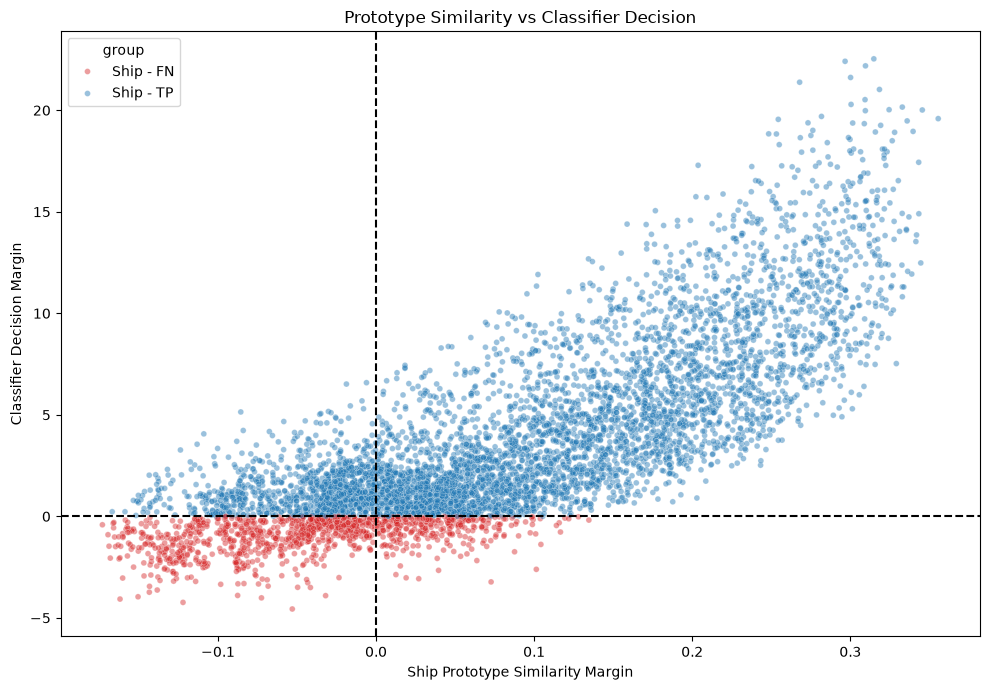

In [34]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=ship_margin_df,
    x="similarity_margin",
    y="classifier_margin",
    hue="group",
    hue_order=["Ship - FN", "Ship - TP"],
    palette={"Ship - FN": "tab:red", "Ship - TP": "tab:blue"},
    alpha=0.45,
    s=18,
)

plt.axhline(0, color="black", linestyle="--")
plt.axvline(0, color="black", linestyle="--")

plt.xlabel("Ship Prototype Similarity Margin")
plt.ylabel("Classifier Decision Margin")
plt.title("Prototype Similarity vs Classifier Decision")

plt.tight_layout()
plt.show()


In [35]:
false_negatives = ship_margin_df[ship_margin_df["group"] == "Ship - FN"].copy()

positive_similarity_fn = false_negatives[
    false_negatives["similarity_margin"] > 0
]

negative_similarity_fn = false_negatives[
    false_negatives["similarity_margin"] <= 0
]

print("FALSE NEGATIVE ANALYSIS")
print("=" * 45)

print(f"Total false negatives: {len(false_negatives):,}")

print(
    f"Positive prototype margin: "
    f"{len(positive_similarity_fn):,} "
    f"({len(positive_similarity_fn) / len(false_negatives) * 100:.2f}%)"
)

print(
    f"Negative prototype margin: "
    f"{len(negative_similarity_fn):,} "
    f"({len(negative_similarity_fn) / len(false_negatives) * 100:.2f}%)"
)

print("\nPositive-margin false negatives:")
display(
    positive_similarity_fn[
        [
            "ImageId",
            "coverage_percent",
            "ship_similarity",
            "no_ship_similarity",
            "similarity_margin",
            "classifier_margin",
        ]
    ]
    .sort_values("similarity_margin", ascending=False)
    .head(15)
)


FALSE NEGATIVE ANALYSIS
Total false negatives: 1,147
Positive prototype margin: 322 (28.07%)
Negative prototype margin: 825 (71.93%)

Positive-margin false negatives:


,ImageId,coverage_percent,ship_similarity,no_ship_similarity,similarity_margin,classifier_margin
91,988e97dc8.jpg,0.283644,0.717537,0.582896,0.134641,-0.183119
6753,41d1f4c43.jpg,1.571147,0.706715,0.578682,0.128033,-0.021535
18654,7aad1af41.jpg,0.225661,0.669374,0.547472,0.121902,-0.117168
8324,d279c3430.jpg,0.198025,0.593492,0.474022,0.119471,-0.084707
18957,7d685601f.jpg,0.126139,0.537993,0.421328,0.116665,-0.770321
947,014bf2cb5.jpg,0.033739,0.510937,0.395063,0.115874,-0.316198
11136,1faf331a9.jpg,0.206672,0.537226,0.423132,0.114094,-0.446783
6648,2879979bb.jpg,0.112406,0.620344,0.516048,0.104296,-1.381390
10715,70684ce9b.jpg,0.113932,0.502137,0.398244,0.103893,-0.111754
27840,88109ce2d.jpg,1.938714,0.544955,0.443566,0.101389,-2.608120


In [37]:
false_negative_comparison = false_negatives.copy()

false_negative_comparison["representation_group"] = np.where(
    false_negative_comparison["similarity_margin"] > 0,
    "Positive prototype margin",
    "Negative prototype margin",
)

display(
    false_negative_comparison.groupby("representation_group").agg(
        images=("ImageId", "count"),
        median_coverage=("coverage_percent", "median"),
        median_ship_similarity=("ship_similarity", "median"),
        median_no_ship_similarity=("no_ship_similarity", "median"),
        median_classifier_margin=("classifier_margin", "median"),
    )
)


,images,median_coverage,median_ship_similarity,median_no_ship_similarity,median_classifier_margin
representation_group,,,,,
Negative prototype margin,825,0.057983,0.323223,0.408834,-0.84253
Positive prototype margin,322,0.058916,0.457456,0.410003,-0.39845


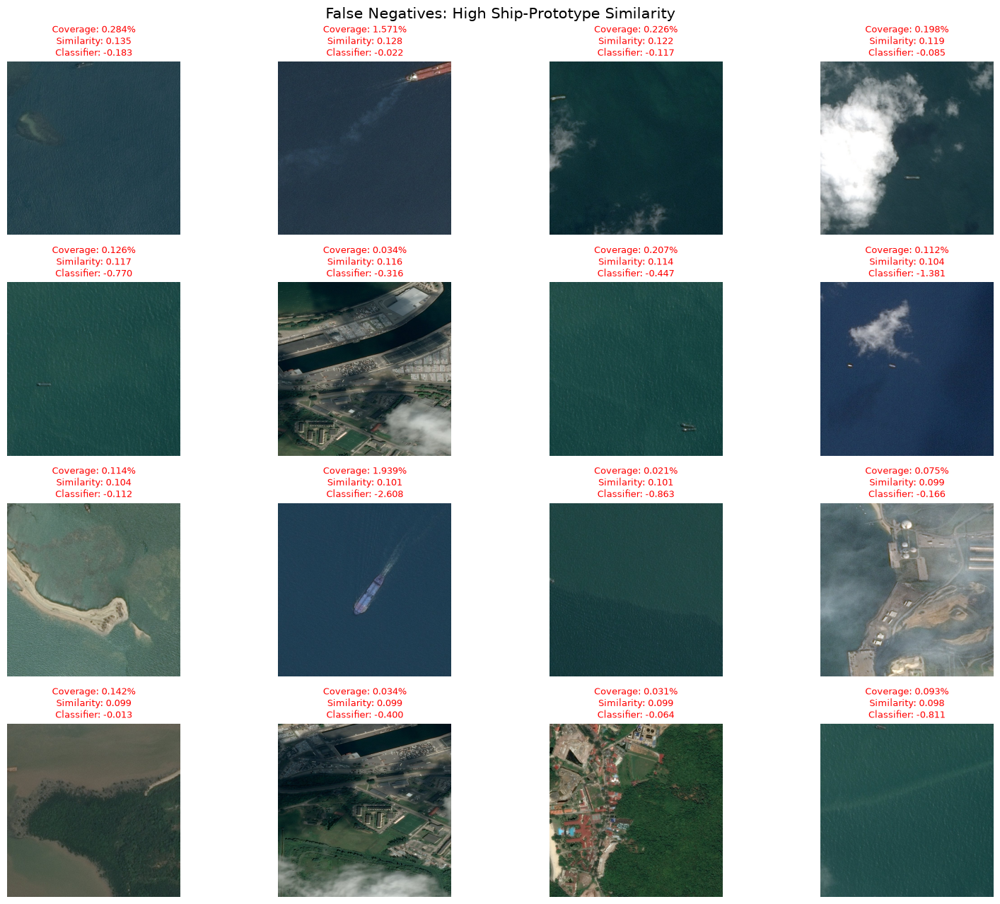

In [38]:
# Select the strongest prototype-matching false negatives
top_positive_fn = positive_similarity_fn.nlargest(16, "similarity_margin")

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
axes = axes.flatten()

for ax, (_, row) in zip(axes, top_positive_fn.iterrows()):
    image_path = DATA_DIR / row["ImageId"]

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"Coverage: {row['coverage_percent']:.3f}%\n"
        f"Similarity: {row['similarity_margin']:.3f}\n"
        f"Classifier: {row['classifier_margin']:.3f}",
        color="red",
        fontsize=9,
    )

    ax.axis("off")

plt.suptitle("False Negatives: High Ship-Prototype Similarity", fontsize=15)

plt.tight_layout()
plt.show()


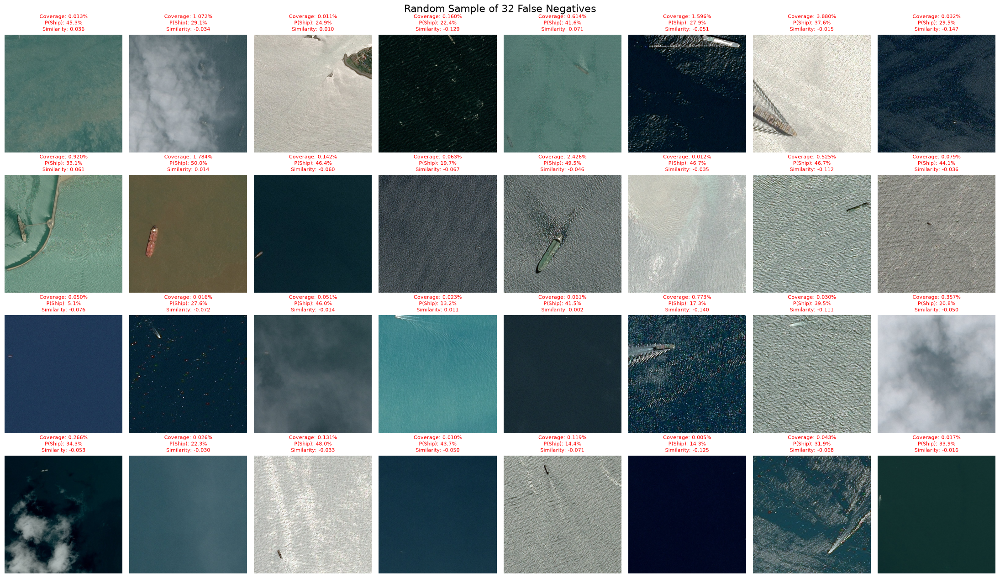

In [39]:
# Randomly sample 32 false negatives
sampled_fn = false_negatives.sample(
    n=min(32, len(false_negatives)), random_state=SEED
)

fig, axes = plt.subplots(4, 8, figsize=(22, 13))
axes = axes.flatten()

for ax, (idx, row) in zip(axes, sampled_fn.iterrows()):
    image_path = DATA_DIR / row["ImageId"]

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    # Probability of the actual Ship class
    ship_probability = test_probabilities[idx, 1]

    ax.set_title(
        f"Coverage: {row['coverage_percent']:.3f}%\n"
        f"P(Ship): {ship_probability:.1%}\n"
        f"Similarity: {row['similarity_margin']:.3f}",
        color="red",
        fontsize=8,
    )

    ax.axis("off")

plt.suptitle("Random Sample of 32 False Negatives", fontsize=16)

plt.tight_layout()
plt.show()


In [40]:
manual_review = sampled_fn.reset_index().rename(
    columns={"index": "test_index"}
)

manual_review.insert(0, "review_id", range(len(manual_review)))

manual_review["visual_category"] = ""

review_columns = [
    "review_id",
    "ImageId",
    "coverage_percent",
    "similarity_margin",
    "classifier_margin",
    "visual_category",
]

display(manual_review[review_columns])


,review_id,ImageId,coverage_percent,similarity_margin,classifier_margin,visual_category
0,0,3cc1bdaa3.jpg,0.012885,0.035846,-0.189730,
1,1,cd2d5bc45.jpg,1.072015,-0.033794,-0.889749,
2,2,cff7acdba.jpg,0.010851,0.010155,-1.103168,
3,3,0c4e8d6de.jpg,0.159878,-0.128820,-1.243810,
4,4,8bd94f511.jpg,0.614081,0.071008,-0.338629,
5,5,c9557d7a3.jpg,1.595561,-0.050811,-0.951506,
6,6,c9ae601a5.jpg,3.880310,-0.014799,-0.505370,
7,7,a3731ee7e.jpg,0.031535,-0.147377,-0.868933,
8,8,920dd8351.jpg,0.919935,0.061123,-0.701738,
9,9,1b8be1300.jpg,1.784092,0.013823,-0.001438,


In [41]:
visual_labels = {
    # Example:
    # 0: "visible",
    # 1: "difficult",
    # 2: "ambiguous",
    0: "difficult",
    1: "visible",
    2: "difficult",
    3: "difficult",
    4: "visible",
    5: "visible",
    6: "visible",
    7: "difficult",
    8: "visible",
    9: "visible",
    10: "difficult",
    11: "difficult",
    12: "visible",
    13: "difficult",
    14: "ambiguous",
    15: "difficult",
    16: "difficult",
    17: "difficult",
    18: "difficult",
    19: "difficult",
    20: "difficult",
    21: "visible",
    22: "difficult",
    23: "difficult",
    24: "difficult",
    25: "difficult",
    26: "visible",
    27: "difficult",
    28: "difficult",
    29: "visible",
    30: "difficult",
    31: "difficult",
}

manual_review["visual_category"] = manual_review["review_id"].map(
    visual_labels
)

print(manual_review["visual_category"].value_counts())

display(manual_review[review_columns])


visual_category
difficult    21
visible      10
ambiguous     1
Name: count, dtype: int64


,review_id,ImageId,coverage_percent,similarity_margin,classifier_margin,visual_category
0,0,3cc1bdaa3.jpg,0.012885,0.035846,-0.189730,difficult
1,1,cd2d5bc45.jpg,1.072015,-0.033794,-0.889749,visible
2,2,cff7acdba.jpg,0.010851,0.010155,-1.103168,difficult
3,3,0c4e8d6de.jpg,0.159878,-0.128820,-1.243810,difficult
4,4,8bd94f511.jpg,0.614081,0.071008,-0.338629,visible
5,5,c9557d7a3.jpg,1.595561,-0.050811,-0.951506,visible
6,6,c9ae601a5.jpg,3.880310,-0.014799,-0.505370,visible
7,7,a3731ee7e.jpg,0.031535,-0.147377,-0.868933,difficult
8,8,920dd8351.jpg,0.919935,0.061123,-0.701738,visible
9,9,1b8be1300.jpg,1.784092,0.013823,-0.001438,visible


In [42]:
manual_review_summary = manual_review.groupby("visual_category").agg(
    images=("ImageId", "count"),
    median_coverage=("coverage_percent", "median"),
    mean_coverage=("coverage_percent", "mean"),
    median_similarity=("similarity_margin", "median"),
    mean_similarity=("similarity_margin", "mean"),
    median_classifier_margin=("classifier_margin", "median"),
    mean_classifier_margin=("classifier_margin", "mean"),
)

display(manual_review_summary)


,images,median_coverage,mean_coverage,median_similarity,mean_similarity,median_classifier_margin,mean_classifier_margin
visual_category,,,,,,,
ambiguous,1,0.524563,0.524563,-0.111924,-0.111924,-0.131557,-0.131557
difficult,21,0.042894,0.075156,-0.050487,-0.048892,-0.759432,-0.891238
visible,10,0.995975,1.320072,-0.033436,-0.029791,-0.603554,-0.684043


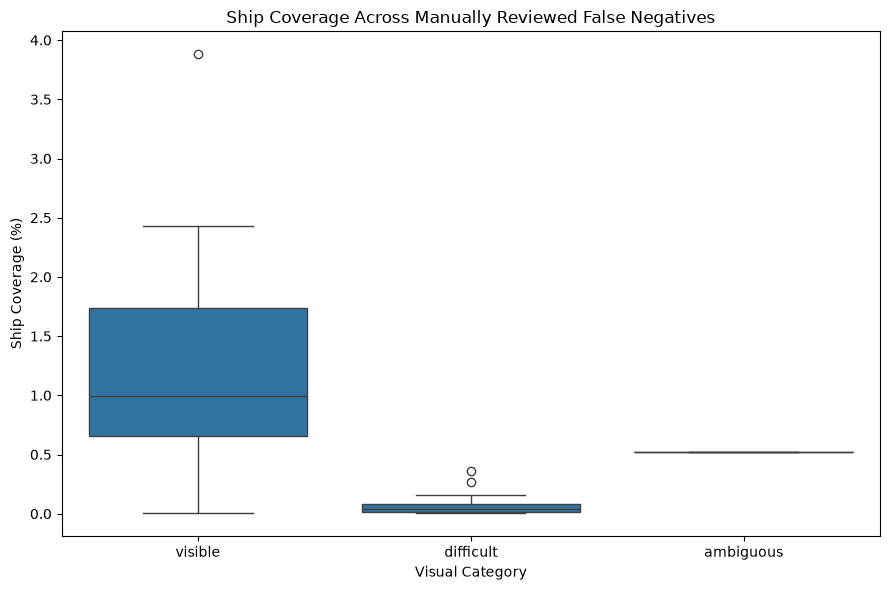

In [43]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=manual_review,
    x="visual_category",
    y="coverage_percent",
    order=["visible", "difficult", "ambiguous"],
)

plt.xlabel("Visual Category")
plt.ylabel("Ship Coverage (%)")
plt.title("Ship Coverage Across Manually Reviewed False Negatives")
plt.tight_layout()
plt.show()


### Results: Manual Review of False Negatives

A random sample of 32 false-negative predictions was manually reviewed and categorized based on the visual visibility of ships.

| Category  | Images | Median Ship Coverage | Mean Ship Coverage |
| --------- | -----: | -------------------: | -----------------: |
| Visible   |     10 |               0.996% |             1.320% |
| Difficult |     21 |               0.043% |             0.075% |
| Ambiguous |      1 |               0.525% |             0.525% |

**Key Observations:**

- 10 images (31.25%) contained visually identifiable ships.
- 21 images (65.63%) contained ships that were difficult to identify visually.
- 1 image (3.12%) was ambiguous.
- Difficult images generally had considerably lower ship coverage than visible images.
- Visible ships were also missed, indicating that small ship size is not the only cause of false negatives.
- The median classifier margin was negative across all three categories, meaning the classifier assigned the no-ship class a higher score.

**Conclusion:**

The manual review indicates two possible sources of false negatives: difficulty detecting very small ships and limitations in the learned representations or classification boundary, even when ships are visually identifiable. These findings suggest that improving small-object representation and feature discrimination should be investigated further.

_Note: This analysis is based on a sample of 32 false negatives and should be treated as exploratory rather than representative of all false-negative predictions._


In [44]:
# Calculate ship coverage for ship-containing training images

train_ship_images = train_df[train_df["has_ship"] == 1]["ImageId"].tolist()

train_size_stats = []

for image_id in train_ship_images:
    stats = get_ship_statistics(image_id)
    train_size_stats.append(
        {"ImageId": image_id, "coverage_percent": stats["coverage_percent"]}
    )

train_size_df = pd.DataFrame(train_size_stats)

threshold = 0.1
above_threshold = (train_size_df["coverage_percent"] >= threshold).sum()
below_threshold = (train_size_df["coverage_percent"] < threshold).sum()

print(f"Total ship-containing training images: {len(train_size_df):,}")
print(
    f"Coverage >= {threshold}%: {above_threshold:,} "
    f"({above_threshold / len(train_size_df) * 100:.2f}%)"
)
print(
    f"Coverage < {threshold}%: {below_threshold:,} "
    f"({below_threshold / len(train_size_df) * 100:.2f}%)"
)

Total ship-containing training images: 29,789
Coverage >= 0.1%: 17,976 (60.34%)
Coverage < 0.1%: 11,813 (39.66%)
